# 05 Calibration

This notebook fits a simple gravity model to real attendance of attractions along the Klint.

**Model.** Visitors to attraction j = k × Σ over origins i of P_i × exp(-β × t_ij), where P_i is the population of origin i and t_ij the car travel time in minutes (notebook 04). β is the distance decay: how quickly interest falls with travel time. k is an overall scale.

**Why only k and β.** We have 8 attendance figures. Giving each attraction its own attractiveness would fit the data perfectly and predict nothing. Instead, the ratio observed / predicted for each site is read as its **attractiveness factor**, which notebook 06 uses to build low/base/high scenarios for the new museum.

**Attendance data.** `data/attendance_by_year.csv`: official figures from GBUK LO "Museum Agency" (letter of 12.11.2026, publication allowed with credit) for Slantsy, Kingisepp, Ivangorod, Koporye and Izvara; Putilovo from the park's reply; Staraya Ladoga (2021) and Oreshek (2023) from press reports. Years with a flag (closed for repairs, 2026 petrol crisis) are excluded, and the latest remaining year is used. Sablino is not used: cave tours are capped and most visitors cannot be counted.

**Fit.** In log space (each site counts equally, whether it has 5,000 or 200,000 visitors), with scipy `least_squares`. Checked with leave-one-out.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

PROCESSED = "../data/processed"

origins = pd.read_csv(f"{PROCESSED}/origins.csv")
tt = pd.read_csv(f"{PROCESSED}/travel_times.csv").set_index("origin_id")
att = pd.read_csv("../data/attractions.csv")
years = pd.read_csv("../data/attendance_by_year.csv")

# population of the 3,440 origins that have travel times (inner join)
pop = origins.set_index("origin_id")["population"].reindex(tt.index)
assert pop.notna().all()
print(f"Origins: {len(tt):,}, population {pop.sum():,.0f}")

# names must match across files
assert set(att["name_en"]) == set(tt.columns)
assert set(years["name_en"]) <= set(att["name_en"]), set(years["name_en"]) - set(att["name_en"])

# reference value: latest year without a flag
ok = years[years["flag"].isna()]
ref = ok.sort_values("year").groupby("name_en").tail(1).set_index("name_en")
avg = ok[ok["year"].between(2023, 2025)].groupby("name_en")["visitors"].mean()  # for a sensitivity check

calib = (att.loc[att["role"] == "calibration", ["name_en", "type"]]
            .set_index("name_en")
            .join(ref[["year", "visitors"]], how="inner"))
calib["avg_23_25"] = avg.round(0)
calib = calib.sort_values("visitors", ascending=False)
print(f"Calibration points: {len(calib)}")
calib

Origins: 3,440, population 8,265,011
Calibration points: 8


,type,year,visitors,avg_23_25
name_en,,,,
Oreshek Fortress (Shlisselburg),fortress,2023,198000,198000.0
Staraya Ladoga Museum-Reserve,museum-reserve,2021,140000,NaN
Koporye Fortress,fortress,2025,47179,42444.0
Ivangorod Museum (fortress and galleries),fortress / museum,2025,40656,39194.0
Putilovo Paleopark (fossil digging),geology park,2025,13000,11667.0
Roerich Estate Museum (Izvara),museum,2025,10713,10148.0
Kingisepp Local History Museum,museum,2025,9377,8704.0
Slantsy Local History Museum,museum,2025,4645,4645.0


## Fitting k and β

For each attraction we compute its **accessibility**: everyone in the study area, weighted by exp(-β × travel time). People 30 minutes away count almost fully, people 4 hours away count very little. Predicted visitors = k × accessibility.

The fit picks the k and β that make predicted and observed attendance as close as possible on a log scale. Two checks follow:
- **β profile:** how the error changes as β changes. A clear dip means the data pins β down; a flat curve means many values of β fit almost equally well.
- **Predicted vs observed:** points on the diagonal are explained by location alone. The **attractiveness factor** (observed / predicted) shows how much more (above 1) or less (below 1) a site attracts than its location explains.

β is easier to read as a **half-time**: ln 2 / β = the extra driving time after which interest halves.

In [4]:
from scipy.special import logsumexp

T = tt[calib.index].to_numpy()   # minutes, origins x calibration sites
P = pop.to_numpy()
y = np.log(calib["visitors"].to_numpy())

def log_access(beta, T):
    # log of sum_i P_i * exp(-beta * t_ij), computed without numbers becoming 0
    return logsumexp(-beta * T, b=P[:, None], axis=0)

def residuals(params, y, T):
    log_k, beta = params
    return y - (log_k + log_access(beta, T))

def fit_model(y, T):
    res = least_squares(residuals, x0=[np.log(0.01), 0.02], args=(y, T),
                        bounds=([-np.inf, 0.0], [np.inf, 0.2]))
    return res.x   # log_k, beta

log_k, beta = fit_model(y, T)
resid = residuals([log_k, beta], y, T)
rmse = np.sqrt(np.mean(resid ** 2))

print(f"beta = {beta:.4f} per minute (interest halves every {np.log(2) / beta:.0f} min of driving)")
print(f"k = {np.exp(log_k):.5f}")
print(f"Typical error: x{np.exp(rmse):.2f} (RMSE in log space {rmse:.2f})")

calib["predicted"] = np.exp(log_k + log_access(beta, T)).round(0)
calib["factor"] = (calib["visitors"] / calib["predicted"]).round(2)
calib[["type", "visitors", "predicted", "factor"]]

beta = 0.0214 per minute (interest halves every 32 min of driving)
k = 0.04226
Typical error: x3.03 (RMSE in log space 1.11)


,type,visitors,predicted,factor
name_en,,,,
Oreshek Fortress (Shlisselburg),fortress,198000,62810.0,3.15
Staraya Ladoga Museum-Reserve,museum-reserve,140000,26487.0,5.29
Koporye Fortress,fortress,47179,31352.0,1.50
Ivangorod Museum (fortress and galleries),fortress / museum,40656,15478.0,2.63
Putilovo Paleopark (fossil digging),geology park,13000,52578.0,0.25
Roerich Estate Museum (Izvara),museum,10713,34605.0,0.31
Kingisepp Local History Museum,museum,9377,21362.0,0.44
Slantsy Local History Museum,museum,4645,10279.0,0.45


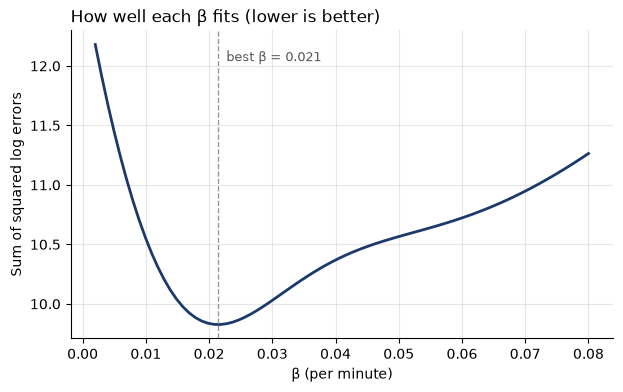

In [5]:
# β profile: for each β, the best k and the remaining error
betas = np.linspace(0.002, 0.08, 80)
sse = []
for b in betas:
    r = y - log_access(b, T)
    sse.append(np.sum((r - r.mean()) ** 2))   # r.mean() = best log k for this β

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(betas, sse, color="#1b3a6b", lw=2)
ax.axvline(beta, color="#999999", ls="--", lw=1)
ax.annotate(f"best β = {beta:.3f}", (beta, max(sse)), xytext=(6, -12),
            textcoords="offset points", fontsize=9, color="#555555")
ax.set_xlabel("β (per minute)")
ax.set_ylabel("Sum of squared log errors")
ax.set_title("How well each β fits (lower is better)", loc="left")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

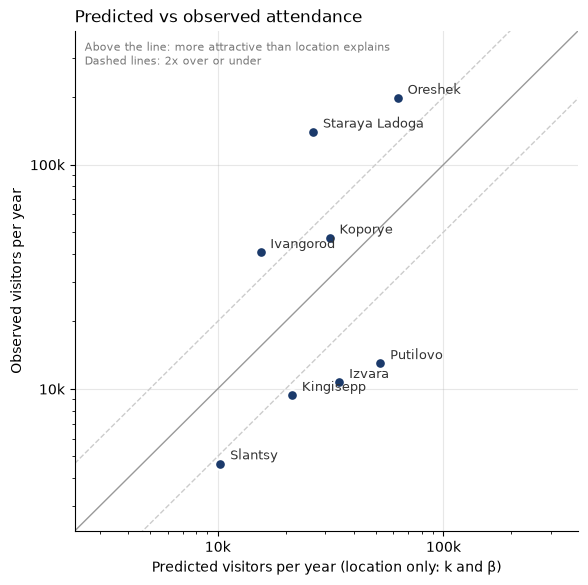

In [6]:
# predicted vs observed
from matplotlib.ticker import FuncFormatter

SHORT = {
    "Oreshek Fortress (Shlisselburg)": "Oreshek",
    "Staraya Ladoga Museum-Reserve": "Staraya Ladoga",
    "Koporye Fortress": "Koporye",
    "Ivangorod Museum (fortress and galleries)": "Ivangorod",
    "Putilovo Paleopark (fossil digging)": "Putilovo",
    "Roerich Estate Museum (Izvara)": "Izvara",
    "Kingisepp Local History Museum": "Kingisepp",
    "Slantsy Local History Museum": "Slantsy",
}

vals = pd.concat([calib["visitors"], calib["predicted"]])
lims = [vals.min() / 2, vals.max() * 2]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.plot(lims, lims, color="#999999", lw=1)
for f in (0.5, 2):
    ax.plot(lims, [l * f for l in lims], color="#cccccc", lw=1, ls="--")
ax.scatter(calib["predicted"], calib["visitors"], s=60, color="#1b3a6b",
           edgecolor="white", linewidth=1.5, zorder=3)
for name, r in calib.iterrows():
    ax.annotate(SHORT[name], (r["predicted"], r["visitors"]), xytext=(7, 3),
                textcoords="offset points", fontsize=9, color="#333333")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lims)
ax.set_ylim(lims)
fmt = FuncFormatter(lambda v, _: f"{v / 1000:g}k")
ax.xaxis.set_major_formatter(fmt)
ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel("Predicted visitors per year (location only: k and β)")
ax.set_ylabel("Observed visitors per year")
ax.set_title("Predicted vs observed attendance", loc="left")
ax.text(0.02, 0.98, "Above the line: more attractive than location explains\n"
        "Dashed lines: 2x over or under", transform=ax.transAxes,
        va="top", fontsize=8, color="#777777")
ax.grid(alpha=0.3, which="major")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("../figures/05_predicted_vs_observed.png", dpi=200, bbox_inches="tight")
plt.show()

## Heritage class and leave-one-out

The residuals split into two groups: well-known heritage sites (medieval fortresses, Staraya Ladoga) attract 1.5 to 5 times what their location explains, while local museums and the paleopark attract 0.25 to 0.45 times. So we compare two models:

- **Model A:** k and β only (location).
- **Model C:** k, β and one class variable, *heritage* (1 for Oreshek, Staraya Ladoga, Koporye, Ivangorod; 0 otherwise). exp(γ) says how many times more a heritage site attracts.

**Leave-one-out:** each site is removed in turn, the model is fitted on the other 7, and the removed site is predicted. This shows how well the model predicts a site it has never seen, which is the situation of the new museum in Slantsy. It also gives a range of β instead of one value.

In [7]:
# model C: k, β and a heritage class
HERITAGE = {
    "Oreshek Fortress (Shlisselburg)",
    "Staraya Ladoga Museum-Reserve",
    "Koporye Fortress",
    "Ivangorod Museum (fortress and galleries)",
}
h = calib.index.isin(HERITAGE).astype(float)

def residuals_c(params, y, T, h):
    log_k, gamma, beta = params
    return y - (log_k + gamma * h + log_access(beta, T))

def fit_class(y, T, h):
    res = least_squares(residuals_c, x0=[np.log(0.01), 1.0, 0.02], args=(y, T, h),
                        bounds=([-np.inf, -np.inf, 0.0], [np.inf, np.inf, 0.2]))
    return res.x   # log_k, gamma, beta

log_k_c, gamma, beta_c = fit_class(y, T, h)
rmse_c = np.sqrt(np.mean(residuals_c([log_k_c, gamma, beta_c], y, T, h) ** 2))
print(f"Model C: beta = {beta_c:.4f} (halves every {np.log(2) / beta_c:.0f} min), "
      f"heritage x{np.exp(gamma):.1f}, typical error x{np.exp(rmse_c):.2f}")

# leave-one-out for both models
rows = []
n = len(y)
for j in range(n):
    m = np.arange(n) != j
    lk_a, b_a = fit_model(y[m], T[:, m])
    lk_c, g_c, b_c = fit_class(y[m], T[:, m], h[m])
    acc_a = log_access(b_a, T[:, [j]])[0]
    acc_c = log_access(b_c, T[:, [j]])[0]
    rows.append({
        "name_en": calib.index[j],
        "observed": calib["visitors"].iloc[j],
        "pred_A": np.exp(lk_a + acc_a),
        "beta_A": b_a,
        "pred_C": np.exp(lk_c + g_c * h[j] + acc_c),
        "beta_C": b_c,
    })
loo = pd.DataFrame(rows).set_index("name_en")
loo["error_A"] = loo["observed"] / loo["pred_A"]
loo["error_C"] = loo["observed"] / loo["pred_C"]

for mdl in ["A", "C"]:
    e = np.log(loo[f"error_{mdl}"])
    b = loo[f"beta_{mdl}"]
    print(f"LOO model {mdl}: typical error x{np.exp(np.sqrt(np.mean(e ** 2))):.2f}, "
          f"beta {b.min():.4f} to {b.max():.4f} "
          f"(halves every {np.log(2) / b.max():.0f} to {np.log(2) / b.min():.0f} min)")

loo.round({"pred_A": 0, "pred_C": 0, "beta_A": 4, "beta_C": 4, "error_A": 2, "error_C": 2})

Model C: beta = 0.0158 (halves every 44 min), heritage x8.4, typical error x1.41
LOO model A: typical error x4.22, beta 0.0097 to 0.0300 (halves every 23 to 71 min)
LOO model C: typical error x1.66, beta 0.0120 to 0.0189 (halves every 37 to 58 min)


,observed,pred_A,beta_A,pred_C,beta_C,error_A,error_C
name_en,,,,,,,
Oreshek Fortress (Shlisselburg),198000,32970.0,0.0097,115898.0,0.0120,6.01,1.71
Staraya Ladoga Museum-Reserve,140000,20749.0,0.0231,63396.0,0.0170,6.75,2.21
Koporye Fortress,47179,29562.0,0.0212,109884.0,0.0161,1.60,0.43
Ivangorod Museum (fortress and galleries),40656,11277.0,0.0300,61086.0,0.0132,3.61,0.67
Putilovo Paleopark (fossil digging),13000,74870.0,0.0297,19021.0,0.0189,0.17,0.68
Roerich Estate Museum (Izvara),10713,41298.0,0.0230,11780.0,0.0161,0.26,0.91
Kingisepp Local History Museum,9377,24477.0,0.0195,7285.0,0.0162,0.38,1.29
Slantsy Local History Museum,4645,19318.0,0.0100,3889.0,0.0174,0.24,1.19
